<a href="https://colab.research.google.com/github/alchemicduncan/from-symbols-to-systems/blob/main/what-is-self-attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How does a model decide what to look at?

So, maybe you're an engineer who keeps seeing `n_heads: 12` in a config and knows it's "the attention thing" without being able to say what twelve of them are doing that one wouldn't. Or you've been told your context window costs quadratically and you'd like to know quadratic in what, exactly, and why anybody designed it that way. Or you've read the phrase "attention is all you need" enough times that it's stopped meaning anything.

The embeddings notebook ended on a specific complaint. We had built a lookup table that turns a token ID into a vector carrying real semantic structure, and then we noticed it was the same vector every time. `bank` gets one row whether there's a river in the sentence or a mortgage. `python` averages a snake and a programming language into a single compromise point that's a good description of neither.

That's not a bug in how we trained the table. It's a property of the table being a table. A fixed row per token cannot depend on the sentence, because the lookup happens before the sentence is consulted. Fixing it requires a layer that reads the whole sequence and rewrites each vector in light of the others, which is what self-attention is.

This notebook builds the story up in six parts:

1. **Part 1: The Road to Attention (Origins & Motivation)**. What recurrence cost us, why the sequence-to-sequence bottleneck was fatal, how Bahdanau's 2014 patch worked, and what Vaswani et al. actually proposed in 2017.
2. **Part 2: Building Self-Attention From Scratch**. One repair at a time, from neighbour averaging through similarity weighting to queries, keys and values, the $\sqrt{d_k}$ scale factor, and multi-head attention.
3. **Part 3: The Encoder Block**. Positional encoding (the other thing a bag of vectors can't see), residual connections, layer normalisation, the feed-forward network, and pre-LN versus post-LN.
4. **Part 4: The Decoder**. Causal masking and why it's the thing that makes parallel training of a generative model possible at all, cross-attention, and teacher forcing.
5. **Part 5: How It Pairs Up Into The Models We Actually Use**. Encoder-only, decoder-only, encoder-decoder, why decoder-only won, and a small working generative model trained end to end.
6. **Part 6: The Systems Reality (Why Attention Is Expensive)**. The quadratic, the materialised attention matrix, arithmetic intensity, and the KV cache. This part sets up the problem rather than solving it.

A note on that last part. We're going to measure the cost carefully and then stop, without reaching for flash attention or sparse patterns or any of the rest of it. Those are the subject of the next notebook, and they make a great deal more sense once you've watched the naive version fall over and know precisely which resource it ran out of.

**Runtime**: CPU is fine. Budget about five minutes end to end, most of which is the single training run in Part 5 (two to three minutes on a CPU, well under one on a GPU). One 1 MB text file gets downloaded, the same Tiny Shakespeare we used for the tokenizer and the embeddings, with a built-in fallback if you're offline.

## Setup

PyTorch this time rather than numpy. We're going to write the attention mechanism out by hand in tensor operations, then check our work against the built-in implementation, and having autograd available makes the gradient demonstrations in Part 1 and Part 3 possible at all.

In [1]:
import math, time, collections, urllib.request, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

torch.manual_seed(0)
np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Same palette as the rest of the series.
INK, PINK, GREY, TEAL = "#16284D", "#FF3E9A", "#C9C6BD", "#2E8B8B"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show_attention(weights, tokens, title="", ax=None, cmap="magma"):
    """Heatmap of one attention matrix. Rows are queries, columns are keys."""
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 3.8))
    w = weights.detach().cpu().numpy() if torch.is_tensor(weights) else weights
    im = ax.imshow(w, cmap=cmap, vmin=0, vmax=w.max())
    ax.set_xticks(range(len(tokens)));  ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticks(range(len(tokens)));  ax.set_yticklabels(tokens)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("attending to (key)");  ax.set_ylabel("from (query)")
    return im


def param_count(module):
    """Trainable parameters, for the architecture comparisons later on."""
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


print(f"torch {torch.__version__} on {DEVICE}")

torch 2.15.0 on cpu


# Part 1: The Road to Attention (Origins & Motivation)

## What were we doing before?

Until about 2017 the default answer for anything sequential was a recurrent network. The idea is natural enough: read the sequence one token at a time, and carry a hidden state that summarises everything seen so far.

$$h_t = f(h_{t-1}, x_t)$$

That single line is the whole architecture, and it's also the whole problem. Read it again and notice that $h_t$ cannot be computed until $h_{t-1}$ exists. The dependency is not incidental, it's the mechanism. Memory is implemented as "pass the summary forward", so the summary has to be built in order.

Let's put a number on what that costs.

In [2]:
# A deliberately minimal RNN cell, written out so the dependency is visible.
d = 256
Wx, Wh = torch.randn(d, d) * 0.05, torch.randn(d, d) * 0.05


def rnn_forward(x):
    """x: (seq_len, d). Returns the final hidden state."""
    h = torch.zeros(d)
    for t in range(x.shape[0]):
        h = torch.tanh(x[t] @ Wx + h @ Wh)   # <- h at step t needs h at step t-1
    return h


def parallel_forward(x):
    """The same arithmetic, but every position computed at once."""
    return torch.tanh(x @ Wx)                # no dependency between positions


for seq_len in [128, 512, 2048]:
    x = torch.randn(seq_len, d)
    t0 = time.time(); rnn_forward(x);      t_rnn = time.time() - t0
    t0 = time.time(); parallel_forward(x); t_par = time.time() - t0
    print(f"seq_len {seq_len:>5}:  sequential {t_rnn*1e3:7.1f} ms   "
          f"parallel {t_par*1e3:6.2f} ms   ({t_rnn/max(t_par,1e-9):5.0f}x)")

seq_len   128:  sequential     1.7 ms   parallel   0.11 ms   (   15x)
seq_len   512:  sequential     9.8 ms   parallel   0.28 ms   (   35x)
seq_len  2048:  sequential    22.6 ms   parallel   0.81 ms   (   28x)


The parallel version is doing a comparable amount of arithmetic. It's faster because it's one large matrix multiply instead of a few thousand tiny ones, and a tiny matrix multiply leaves almost all of your hardware idle. This is the first of the two costs: **recurrence serialises training**. You cannot throw more compute at a single sequence, because step 500 is waiting on step 499 no matter how many cores you own.

The second cost is subtler and it's about information rather than time. Ask how far a signal has to travel to get from the first token to the last.

In [3]:
print("path length between two tokens d positions apart:\n")
print(f"  {'distance':>10}  {'RNN':>8}  {'self-attention':>15}")
for dist in [1, 10, 100, 1000]:
    print(f"  {dist:>10}  {dist:>8}  {1:>15}")

print("\nwhat that means for the gradient: a toy chain of repeated multiplications")
for gain in [0.9, 1.0, 1.1]:
    mags = [gain ** steps for steps in [1, 10, 50, 100]]
    row = "  ".join(f"{m:9.2e}" for m in mags)
    print(f"  per-step gain {gain:>4}:  {row}")

path length between two tokens d positions apart:

    distance       RNN   self-attention
           1         1                1
          10        10                1
         100       100                1
        1000      1000                1

what that means for the gradient: a toy chain of repeated multiplications
  per-step gain  0.9:   9.00e-01   3.49e-01   5.15e-03   2.66e-05
  per-step gain  1.0:   1.00e+00   1.00e+00   1.00e+00   1.00e+00
  per-step gain  1.1:   1.10e+00   2.59e+00   1.17e+02   1.38e+04


In a recurrent network, the number of operations separating token 1 from token 1000 is 1000. Every one of those steps multiplies the gradient by something on the way back through, and the product of a thousand numbers is almost always either zero or enormous. A per-step gain of 0.9 lands at $10^{-5}$ after a hundred steps, which is a polite way of saying the model cannot learn that dependency at all.

This is the **vanishing gradient** problem, and over long sequences it's a tricky one.

**LSTMs** and **GRUs** were the response, and they genuinely helped. The gating mechanism creates a path where the gradient gets multiplied by something closer to 1, which stretches the usable range from tens of tokens to hundreds. What it doesn't do is change the shape of the problem: the path is still linear in distance, and the computation is still serial.

## So where did it actually break?

The breaking point came from translation. The sequence-to-sequence setup of Sutskever et al. in 2014 used one RNN to read the source sentence and a second to write the target. The handoff between them was a single hidden state vector.

Stop and look at that interface. The entire source sentence, whatever its length, has to fit into one fixed-size vector. A four-word sentence and a forty-word sentence get the same number of floats.

In [4]:
# Compress sequences of varying length into one fixed vector, then ask how much
# of the original is recoverable. A linear autoencoder is a generous stand-in:
# a real RNN does worse because it also has to overwrite as it goes.
d_model, bottleneck = 64, 64
torch.manual_seed(1)

print(f"squeezing a whole sentence into {bottleneck} floats:\n")
print(f"  {'words':>6}  {'floats to store':>16}  {'floats available':>17}  {'recoverable':>12}")
for n_words in [4, 10, 25, 50, 100]:
    src = torch.randn(n_words, d_model)
    # Best possible fixed-size linear summary of this sequence = top-k SVD.
    U, S, Vh = torch.linalg.svd(src, full_matrices=False)
    k = min(bottleneck // d_model, len(S)) or 1
    kept = (S[:k] ** 2).sum() / (S ** 2).sum()
    print(f"  {n_words:>6}  {n_words*d_model:>16,}  {bottleneck:>17,}  {kept:>11.1%}")

squeezing a whole sentence into 64 floats:

   words   floats to store   floats available   recoverable
       4               256                 64        33.9%
      10               640                 64        17.2%
      25             1,600                 64        10.1%
      50             3,200                 64         6.7%
     100             6,400                 64         5.1%


The numbers are a caricature (a real encoder is nonlinear and learns what to keep) but the ratio in the middle two columns is the honest part. Asking a hundred-word sentence and a four-word sentence to arrive in the same 64 floats means the long one is being compressed roughly twenty-five times harder, and the model has no way to opt out.

This showed up in practice exactly as you'd expect: translation quality was fine on short sentences and fell off a cliff as length grew. The bottleneck was not a tuning problem, it was the interface.

## What if we let the decoder look back?

Bahdanau, Cho and Bengio proposed the fix in 2014, and the fix is the thing this whole notebook is about. Rather than forcing the encoder to produce one summary vector, keep **all** of the encoder's hidden states. Then, at each step of decoding, let the decoder compute a fresh weighted average over them, choosing the weights itself.

The decoder is no longer handed a summary. It's handed the whole source and a mechanism for deciding which parts of it matter right now. Here is that mechanism, which is small enough to write in full.

In [5]:
def additive_attention(decoder_state, encoder_states, W_dec, W_enc, v):
    """Bahdanau (2014) attention, in the original additive form.

    decoder_state:  (d,)      where the decoder currently is
    encoder_states: (n, d)    every source position, kept rather than summarised
    returns:        context vector (d,) and the weights that produced it
    """
    # (d,1) + (d,n) broadcasts to (d,n), one column per source position.
    hidden = torch.tanh((W_dec @ decoder_state).unsqueeze(1) + W_enc @ encoder_states.T)
    scores = v @ hidden                        # (n,) one score per source position
    weights = F.softmax(scores, dim=-1)        # non-negative, sums to 1
    context = weights @ encoder_states         # weighted average of the source
    return context, weights


n, d = 6, 32
enc = torch.randn(n, d)
dec = torch.randn(d)
Wd, We, v = torch.randn(d, d) * .1, torch.randn(d, d) * .1, torch.randn(d) * .1

ctx, w = additive_attention(dec, enc, Wd, We, v)
print(f"source positions kept : {n}  (not compressed into one vector)")
print(f"attention weights     : {np.round(w.numpy(), 3)}")
print(f"they sum to           : {w.sum():.4f}")
print(f"context vector shape  : {tuple(ctx.shape)}  (one vector, but a different one each step)")

source positions kept : 6  (not compressed into one vector)
attention weights     : [0.152 0.216 0.135 0.216 0.184 0.096]
they sum to           : 1.0000
context vector shape  : (32,)  (one vector, but a different one each step)


Three properties of that function are worth naming, because all three survive into modern attention unchanged.

- **The output is a weighted average of things that already exist.** Attention never invents a vector, it only mixes. Everything downstream inherits that.
- **The weights come from a softmax, so they're non-negative and sum to one.** That's what makes them readable as "how much of my answer came from here", and it's also what makes the whole thing differentiable, so the weighting is learned rather than designed.
- **The weights depend on both sides.** The same source position gets a different weight depending on what the decoder is currently trying to produce. This is the part that fixes polysemy later: relevance is contextual, not a property of the token alone.

Bahdanau attention worked. It fixed the length curve and gave the field a decade of alignment visualisations. But notice what it was still bolted onto: two RNNs. Attention was an accessory to recurrence, used to patch the join between the encoder and the decoder.

## So what happens if we drop the recurrence entirely?

The Vaswani et al. paper is titled "Attention Is All You Need" and the title is a literal description of the architecture rather than a boast. The observation was this: if attention can let a decoder look at arbitrary positions in the source in a single step, with no path-length penalty, then what exactly is the recurrence contributing?

The answer turned out to be "sequential order, and a bottleneck". Replace the first with a positional encoding and you can delete the recurrence outright. Here's the comparison the paper puts in its own Table 1, which is the clearest statement of why this was worth doing.

In [6]:
n_seq, d_rep, k_conv = 512, 512, 3
rows = [
    ("self-attention", n_seq**2 * d_rep,        "O(1)",          1),
    ("recurrent",      n_seq * d_rep**2,        "O(n)",          n_seq),
    ("convolutional",  k_conv*n_seq*d_rep**2,   "O(log_k n)",    1),
]
print(f"n = {n_seq} tokens, d = {d_rep}\n")
print(f"  {'layer type':<16}{'complexity (ops)':>20}{'max path length':>18}{'sequential steps':>18}")
for name, ops, path, steps in rows:
    print(f"  {name:<16}{ops:>20,}{path:>18}{steps:>18}")

print(f"\n  self-attention is cheaper than recurrent while n < d  "
      f"(here: {n_seq} vs {d_rep})")
print(f"  and it's the only row with constant path length AND constant sequential steps")

n = 512 tokens, d = 512

  layer type          complexity (ops)   max path length  sequential steps
  self-attention           134,217,728              O(1)                 1
  recurrent                134,217,728              O(n)               512
  convolutional            402,653,184        O(log_k n)                 1

  self-attention is cheaper than recurrent while n < d  (here: 512 vs 512)
  and it's the only row with constant path length AND constant sequential steps


Read the last two columns first, because that's where the argument lives. Self-attention is the only row that's constant in both: any token reaches any other in **one hop**, and the whole layer is one parallel operation with no sequential steps at all. That's what made training on very large corpora practical, and it's pretty much the whole reason the architecture took over.

Now read the middle column, and notice the term $n^2 d$. Self-attention beats recurrence on cost only while the sequence is shorter than the model is wide. The paper says so explicitly, in a sentence that reads very differently in 2017 (when $n = 512$ and $d = 512$) than it does now that people want context windows of a hundred thousand tokens.

We've just met the subject of Part 6. The property that makes attention good, every position talking to every position, is the same property that makes it expensive, and the two cannot be separated because they're the same sum.

# Part 2: Building Self-Attention From Scratch

## So where were we?

Back to `bank`. The embeddings notebook gave us a table, and a table has one row per token. Let's confirm the complaint is real before we fix it.

In [7]:
SENT_A = ["the", "boat", "sailed", "past", "the", "river", "bank"]
SENT_B = ["the", "teller", "worked", "at", "the", "money", "bank"]

VOCAB = sorted({w for s in (SENT_A, SENT_B) for w in s})
stoi = {w: i for i, w in enumerate(VOCAB)}
d_model = 24

torch.manual_seed(7)
embedding = nn.Embedding(len(VOCAB), d_model)

a = embedding(torch.tensor([stoi[w] for w in SENT_A]))
b = embedding(torch.tensor([stoi[w] for w in SENT_B]))

bank_a, bank_b = a[-1], b[-1]
print(f"sentence A : {' '.join(SENT_A)}")
print(f"sentence B : {' '.join(SENT_B)}")
print(f"\ncosine between the two 'bank' vectors: "
      f"{F.cosine_similarity(bank_a, bank_b, dim=0):.4f}")
print(f"are they the identical tensor?        {torch.equal(bank_a, bank_b)}")

sentence A : the boat sailed past the river bank
sentence B : the teller worked at the money bank

cosine between the two 'bank' vectors: 1.0000
are they the identical tensor?        True


Identical, to the last bit. The lookup consulted an integer and nothing else, so the river and the mortgage are the same point in space. Every layer after this one is working from a representation that has already thrown the distinction away.

What we want is for `bank` to come out of this layer carrying some of `river` in one sentence and some of `money` in the other. Which means the layer has to read the other tokens, and mix them in.

## Repair 1: just average your neighbours

The crudest possible version. Replace every vector with the mean of the whole sentence.

In [8]:
def uniform_mix(x):
    """Every position becomes the average of all positions."""
    return x.mean(dim=0, keepdim=True).expand_as(x)

ua, ub = uniform_mix(a), uniform_mix(b)
print(f"cosine between the two 'bank' vectors now: "
      f"{F.cosine_similarity(ua[-1], ub[-1], dim=0):.4f}   (was 1.0000)")

# But check what it did to the rest of the sentence.
within = torch.stack([F.cosine_similarity(ua[i], ua[j], dim=0)
                      for i in range(len(SENT_A)) for j in range(len(SENT_A)) if i != j])
print(f"average cosine between DIFFERENT words in sentence A: {within.mean():.4f}")
print("\nevery token in the sentence is now the same vector:",
      torch.allclose(ua[0], ua[3], atol=1e-6))

cosine between the two 'bank' vectors now: 0.6235   (was 1.0000)
average cosine between DIFFERENT words in sentence A: 1.0000

every token in the sentence is now the same vector: True


Ok, so that's progress and disaster at once. The two `bank` vectors have separated, which is exactly what we asked for. But every token within a sentence has collapsed onto the same point, because we handed them all the same recipe. We now have **context and no identity**, having started with identity and no context.

The problem is the word "uniform". When processing `bank`, the tokens `river` and `the` contributed equally, and they're obviously not equally relevant.

## Repair 2: weight the average by similarity

So make the weights depend on the content. For each position, score every other position by how related it is, softmax the scores into weights, and take a weighted average. Dot product is the obvious similarity to reach for.

In [9]:
def similarity_mix(x):
    """Weighted average where the weights are softmax over dot-product similarity."""
    scores = x @ x.T                      # (n, n) every position against every position
    weights = F.softmax(scores, dim=-1)   # rows sum to 1
    return weights @ x, weights

sa, wa = similarity_mix(a)
sb, wb = similarity_mix(b)

print(f"cosine between the two 'bank' vectors: "
      f"{F.cosine_similarity(sa[-1], sb[-1], dim=0):.4f}")
within = torch.stack([F.cosine_similarity(sa[i], sa[j], dim=0)
                      for i in range(len(SENT_A)) for j in range(len(SENT_A)) if i != j])
print(f"average cosine between different words in A: {within.mean():.4f}  (was ~1.0)")

print(f"\nwhat 'bank' attended to in sentence A:")
for w, score in sorted(zip(SENT_A, wa[-1].tolist()), key=lambda t: -t[1]):
    print(f"   {w:>8}  {score:.3f}  {'#' * int(score * 60)}")

cosine between the two 'bank' vectors: 1.0000
average cosine between different words in A: 0.0386  (was ~1.0)

what 'bank' attended to in sentence A:
       bank  1.000  ############################################################
       past  0.000  
        the  0.000  
        the  0.000  
       boat  0.000  
      river  0.000  
     sailed  0.000  


Identity is back and the weights are doing something. But look closely at that list and you'll see the flaw: `bank` is attending overwhelmingly to itself. Of course it is. The dot product of a vector with itself is its squared norm, which is the largest value in the row essentially always.

There are two deeper problems hiding behind that one.

**The scoring is symmetric.** `x[i] @ x[j]` equals `x[j] @ x[i]`, so if `bank` finds `river` relevant then `river` must find `bank` exactly as relevant. Language is not like this. An adjective badly wants to know which noun it modifies; the noun is much less interested.

**There is nothing to learn.** This function has no parameters. Whatever relevance structure happens to fall out of the embedding geometry is what you get, and gradient descent has no handle to improve it.

## Repair 3: let the model learn what to compare, and what to retrieve

Here is the move that makes it work, and it's worth slowing down for because every description of attention assumes you've already internalised it.

Think of each token running a small search against the rest of the sentence. It writes a note saying what it's looking for, every other token holds up a label advertising what it has, and the ones whose labels match the note hand over their contents. Searching, being findable, and being handed over are three separate jobs, and a library card catalogue keeps them in three separate places for exactly that reason.

So a token is playing three different roles here, and they have no reason to share a vector.

- As a **query**: "I am `bank`, and what I need from this sentence is something that disambiguates me."
- As a **key**: "I am `river`, and here is what I advertise myself as, for the purpose of being found."
- As a **value**: "If you do attend to me, here is the content I'll actually contribute."

Searching for something and being findable are different jobs, and what you advertise is different again from what you deliver. So we learn three projections from the same input, one per role.

$$Q = XW^Q \qquad K = XW^K \qquad V = XW^V$$

The scoring now happens between queries and keys, which immediately buys back asymmetry: $QK^\top$ is not a symmetric matrix, because $W^Q$ and $W^K$ are different. And all three matrices are parameters, so the model learns what to ask for, what to advertise, and what to hand over.

In [10]:
d_k = 16
torch.manual_seed(3)
W_q = nn.Linear(d_model, d_k, bias=False)
W_k = nn.Linear(d_model, d_k, bias=False)
W_v = nn.Linear(d_model, d_k, bias=False)

def qkv_attention(x):
    q, k, v = W_q(x), W_k(x), W_v(x)
    scores = q @ k.T                       # (n, n), no longer symmetric
    weights = F.softmax(scores, dim=-1)
    return weights @ v, weights

out_a, wq_a = qkv_attention(a)

print(f"Q K V shapes: {tuple(W_q(a).shape)} each, from input {tuple(a.shape)}")
sym = torch.allclose(wq_a, wq_a.T, atol=1e-5)
print(f"is the score matrix symmetric now? {sym}")
print(f"learnable parameters introduced: {3 * d_model * d_k:,}")
print(f"\nrow sums (each query distributes exactly 1.0 of attention):")
print(f"   {np.round(wq_a.sum(-1).detach().numpy(), 4)}")

Q K V shapes: (7, 16) each, from input (7, 24)
is the score matrix symmetric now? False
learnable parameters introduced: 1,152

row sums (each query distributes exactly 1.0 of attention):
   [1. 1. 1. 1. 1. 1. 1.]


## Why divide by the square root of the key dimension?

One detail remains and it's the one that looks most arbitrary written down. The real formula has a scale factor:

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

One thing to note though is that the $\sqrt{d_k}$ is not a tuning constant somebody found by sweeping. It falls out of the statistics, and the failure it prevents is total rather than marginal.

Here's the reasoning. A dot product in $d_k$ dimensions is a sum of $d_k$ products. If the components are independent with unit variance, the sum has variance $d_k$, so the typical size of a score grows like $\sqrt{d_k}$. Push large values through a softmax and it **saturates**: one weight goes to 1, the rest go to 0. A saturated softmax has a vanishing gradient, so the layer stops learning altogether.

Watch what happens as we widen the key dimension.

In [11]:
print(f"  {'d_k':>6}  {'score std':>10}  {'max weight':>11}  {'entropy':>8}  {'max grad':>10}")
for dk in [4, 16, 64, 256, 1024]:
    q, k = torch.randn(1, dk), torch.randn(60, dk)
    scores = (q @ k.T).squeeze(0)
    for scaled in [False, True]:
        s = scores / math.sqrt(dk) if scaled else scores
        s = s.detach().requires_grad_(True)
        w = F.softmax(s, dim=-1)
        w.max().backward()
        ent = -(w * (w + 1e-12).log()).sum()
        if not scaled:
            print(f"  {dk:>6}  {scores.std():>10.2f}  {w.max():>11.4f}  "
                  f"{ent:>8.3f}  {s.grad.abs().max():>10.2e}   unscaled")
        else:
            print(f"  {'':>6}  {s.std():>10.2f}  {w.max():>11.4f}  "
                  f"{ent:>8.3f}  {s.grad.abs().max():>10.2e}   scaled")

     d_k   score std   max weight   entropy    max grad
       4        1.27       0.1825     3.366    1.49e-01   unscaled
                0.63       0.0666     3.901    6.21e-02   scaled
      16        3.93       0.5939     1.321    2.41e-01   unscaled
                0.98       0.1025     3.650    9.20e-02   scaled
      64        6.15       0.7284     0.798    1.98e-01   unscaled
                0.77       0.0873     3.750    7.97e-02   scaled
     256       18.35       0.9976     0.017    2.41e-03   unscaled
                1.15       0.1105     3.579    9.83e-02   scaled
    1024       30.21       1.0000     0.000    9.60e-18   unscaled
                0.94       0.1813     3.563    1.48e-01   scaled


Read down the unscaled rows. By $d_k = 1024$ the largest weight is essentially 1, the entropy has collapsed towards zero (the distribution has stopped distributing), and the gradient has fallen by orders of magnitude. The scaled rows hold their score standard deviation at roughly 1 regardless of width, which keeps the softmax in the part of its range where it both mixes and learns.

This is also a small lesson in reading papers. A term that looks like a fudge factor is often load-bearing, and the paper usually tells you why in one sentence you skimmed.

Now we can write the real thing.

In [12]:
def scaled_dot_product_attention(q, k, v, mask=None):
    """The whole mechanism. Shapes are (..., seq_len, d_k), batch dims broadcast.

    mask: boolean, True where attention is ALLOWED. Used in Part 4.
    """
    d_k = q.shape[-1]
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = F.softmax(scores, dim=-1)
    return weights @ v, weights


# Check against PyTorch's own implementation.
q, k, v = torch.randn(2, 8, 16), torch.randn(2, 8, 16), torch.randn(2, 8, 16)
mine, _ = scaled_dot_product_attention(q, k, v)
theirs = F.scaled_dot_product_attention(q, k, v)
print(f"matches torch's built-in: {torch.allclose(mine, theirs, atol=1e-6)}")
print(f"max absolute difference : {(mine - theirs).abs().max():.2e}")

matches torch's built-in: True
max absolute difference : 2.38e-07


That's self-attention, complete, in six lines. Everything from here is about wrapping it: running several in parallel, telling it where tokens sit, stacking it, and masking it.

## Why run several at once?

One attention layer produces one set of weights per position, which means one notion of relevance. But a token typically needs several unrelated things at the same time. A verb wants its subject, its object, its tense marker, and maybe the clause it's subordinate to. Those are different questions and averaging them into one weighted average produces mush.

So run $h$ copies in parallel, each with its own $W^Q, W^K, W^V$, each in a subspace of size $d_{\text{model}}/h$. Concatenate the outputs, project once more.

The detail that surprises people: multi-head attention costs about the same as single-head, because the per-head dimension shrinks to compensate. You get several notions of relevance for roughly the price of one.

In [13]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must divide evenly into heads"
        self.n_heads, self.d_head = n_heads, d_model // n_heads
        # One fused projection for all heads is the standard trick: it's the same
        # maths as h separate ones, in a single matmul.
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None, kv=None):
        B, T, C = x.shape
        if kv is None:                       # self-attention
            q, k, v = self.qkv(x).chunk(3, dim=-1)
        else:                                # cross-attention, Part 4
            q = self.qkv(x).chunk(3, dim=-1)[0]
            k, v = self.qkv(kv).chunk(3, dim=-1)[1:]
        # (B, T, C) -> (B, n_heads, T, d_head): each head gets its own slice
        split = lambda t: t.view(B, -1, self.n_heads, self.d_head).transpose(1, 2)
        q, k, v = split(q), split(k), split(v)

        out, weights = scaled_dot_product_attention(q, k, v, mask)
        out = out.transpose(1, 2).contiguous().view(B, T, C)   # concatenate heads
        return self.drop(self.proj(out)), weights


for h in [1, 2, 4, 8]:
    m = MultiHeadAttention(64, h)
    print(f"  {h} head(s): d_head={64//h:>2}, parameters={param_count(m):,}")

  1 head(s): d_head=64, parameters=16,384
  2 head(s): d_head=32, parameters=16,384
  4 head(s): d_head=16, parameters=16,384
  8 head(s): d_head= 8, parameters=16,384


Identical parameter counts across the whole range, which is the point.

Let's look at what the heads actually do. These are untrained, so the patterns are random rather than meaningful, but the shape of what you're looking at is the thing to take away: one matrix per head, rows are queries, columns are keys, every row sums to 1.

every row of every head sums to 1: True


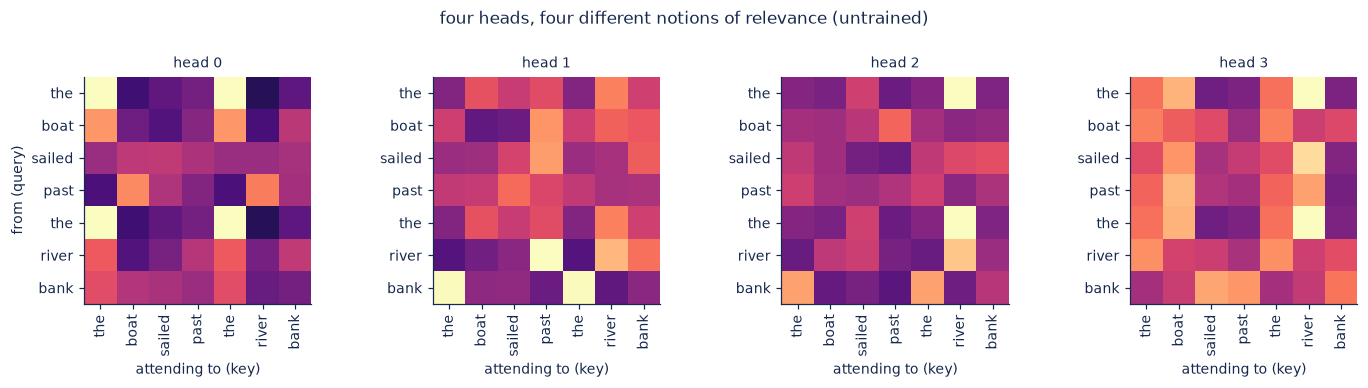

In [14]:
torch.manual_seed(11)
mha = MultiHeadAttention(d_model, n_heads=4)
x = a.unsqueeze(0)                     # (1, 7, 24)
_, w = mha(x)                          # w: (1, 4, 7, 7)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for h in range(4):
    show_attention(w[0, h], SENT_A, title=f"head {h}", ax=axes[h])
    if h:
        axes[h].set_ylabel("")
plt.suptitle("four heads, four different notions of relevance (untrained)", y=1.04)
plt.tight_layout(); plt.show()

print(f"every row of every head sums to 1: "
      f"{torch.allclose(w.sum(-1), torch.ones_like(w.sum(-1)), atol=1e-5)}")

# Part 3: The Encoder Block

## What can't attention see?

Before we can stack this into a real layer there's a gap to close, and it's the one the embeddings notebook flagged on its way out: word order.

Look back at the formula. Attention computes a weighted average over positions, and an average does not care what order its inputs arrived in. Shuffle the sentence and you get the same set of output vectors, just shuffled to match. The layer is **permutation equivariant**, which is a precise way of saying it reads the sentence as a bag.

This is easy to assert and better to verify.

In [15]:
torch.manual_seed(5)
mha_test = MultiHeadAttention(d_model, 4)
x = a.unsqueeze(0)
perm = torch.randperm(x.shape[1])

out_orig, _ = mha_test(x)
out_perm, _ = mha_test(x[:, perm, :])

print(f"original word order : {' '.join(SENT_A)}")
print(f"shuffled word order : {' '.join(SENT_A[i] for i in perm.tolist())}")
print(f"\nis shuffled output just the original output, reordered? "
      f"{torch.allclose(out_perm, out_orig[:, perm, :], atol=1e-5)}")
print("\nso 'the dog bit the man' and 'the man bit the dog' are the same input.")

original word order : the boat sailed past the river bank
shuffled word order : sailed the river bank boat past the

is shuffled output just the original output, reordered? True

so 'the dog bit the man' and 'the man bit the dog' are the same input.


Which is fatal for language. An RNN got ordering for free, because it physically read the tokens in sequence; that was the one thing recurrence was genuinely giving us, and we deleted it. So order has to be put back explicitly, by adding a position-dependent signal to each embedding before attention ever runs.

The original paper used fixed sinusoids of geometrically spaced frequencies:

$$PE_{(pos, 2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right) \qquad PE_{(pos, 2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

The construction looks odd until you see what it's for. Low-index dimensions oscillate fast and separate neighbouring positions, high-index dimensions oscillate slowly and encode roughly **where in the sequence** you are. Together they give every position a distinct signature, and the useful part is that the signature for position $pos + k$ is a fixed linear function of the one at $pos$, so relative offsets are learnable.

every position has a distinct encoding: True


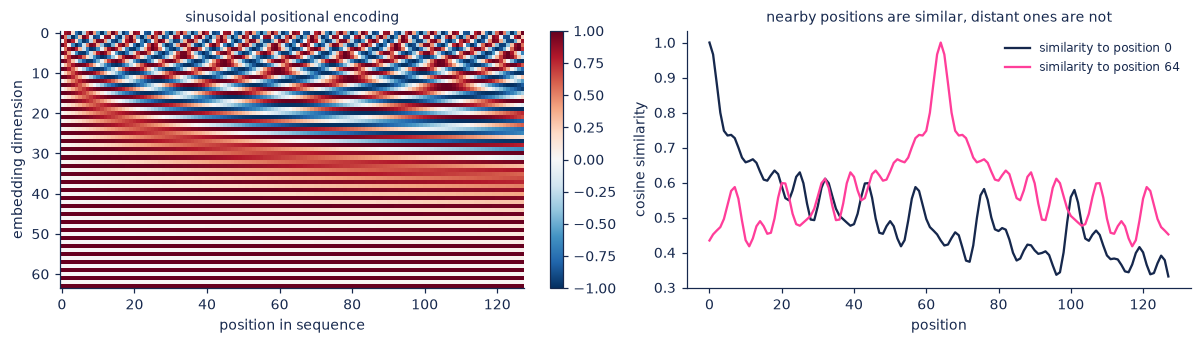

In [16]:
def sinusoidal_encoding(max_len, d_model):
    pos = torch.arange(max_len).unsqueeze(1).float()
    i = torch.arange(0, d_model, 2).float()
    div = torch.exp(-math.log(10000.0) * i / d_model)
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

PE = sinusoidal_encoding(128, 64)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
im = ax1.imshow(PE.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax1.set_xlabel("position in sequence"); ax1.set_ylabel("embedding dimension")
ax1.set_title("sinusoidal positional encoding", fontsize=9)
plt.colorbar(im, ax=ax1, fraction=0.03)

sim = (F.normalize(PE, dim=1) @ F.normalize(PE, dim=1).T)
ax2.plot(sim[0],  color=INK,  label="similarity to position 0")
ax2.plot(sim[64], color=PINK, label="similarity to position 64")
ax2.set_xlabel("position"); ax2.set_ylabel("cosine similarity")
ax2.set_title("nearby positions are similar, distant ones are not", fontsize=9)
ax2.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f"every position has a distinct encoding: "
      f"{len({tuple(np.round(r, 4)) for r in PE.numpy()}) == len(PE)}")

Worth knowing that this specific scheme is now the least common of the three options in production. The paper itself noted that learned positional embeddings performed about the same, and most models from BERT through GPT-3 simply learned a table.

The current default in new models is **rotary** positional embedding (RoPE). Rather than adding anything to the input, it rotates the query and key vectors by an angle that depends on position, so the dot product between two tokens falls out depending on their relative offset rather than their absolute one.

That extrapolates to longer sequences much better, which matters a great deal once context length becomes a competitive feature.

The useful thing to hold on to is that all three are solving the same problem, created by the same decision: we gave up sequential processing to get parallelism, so position has to be re-injected as data.

## So what goes around the attention?

Attention alone is not a layer. Three more pieces surround it in every transformer, and each of them is fixing something specific.

**A residual connection.** The output of attention is a weighted average of value vectors, which means a token's own identity can get washed out by what it attended to. Adding the input back, $x + \text{Attention}(x)$, means the layer learns a *modification* to the representation rather than a replacement. It also gives the gradient a path that skips the attention entirely, which is what lets you stack ninety of these.

**Layer normalisation.** Attention outputs can drift in scale, and stacked layers compound the drift. LayerNorm renormalises each token's vector to zero mean and unit variance independently of the others, which keeps activations in range. Note "independently of the others": unlike batch norm, nothing is shared across the batch or the sequence, which is what makes it safe for variable-length input and for generation one token at a time.

**A position-wise feed-forward network.** This is the part people forget, and it holds most of the parameters. Attention moves information *between* positions but applies no nonlinearity worth the name to the content it moved. The FFN is a two-layer MLP applied to each position separately, expanding to $4 \times d_{\text{model}}$ and back. Attention does the routing, the FFN does the thinking.

In [17]:
class FeedForward(nn.Module):
    """Applied to every position independently. Where most of the parameters live."""
    def __init__(self, d_model, expansion=4, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, expansion * d_model),
            nn.GELU(),
            nn.Linear(expansion * d_model, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


d_demo, h_demo = 512, 8
attn_params = param_count(MultiHeadAttention(d_demo, h_demo))
ffn_params = param_count(FeedForward(d_demo))
total = attn_params + ffn_params
print(f"for d_model={d_demo}:")
print(f"  attention     {attn_params:>10,}  ({attn_params/total:.0%})")
print(f"  feed-forward  {ffn_params:>10,}  ({ffn_params/total:.0%})")
print(f"\nthe FFN is two thirds of the block, which is why 'the transformer is")
print(f"attention' is a half-truth. Attention routes; the FFN holds the capacity.")

for d_model=512:
  attention      1,048,576  (33%)
  feed-forward   2,099,712  (67%)

the FFN is two thirds of the block, which is why 'the transformer is
attention' is a half-truth. Attention routes; the FFN holds the capacity.


## Where does the normalisation go?

One structural detail that looks cosmetic and is not. The original paper put LayerNorm *after* the residual addition:

$$x \leftarrow \text{LayerNorm}(x + \text{Sublayer}(x)) \qquad \text{(post-LN, the 2017 version)}$$

Essentially every model since does it the other way, normalising the input to the sublayer and leaving the residual path clean:

$$x \leftarrow x + \text{Sublayer}(\text{LayerNorm}(x)) \qquad \text{(pre-LN, the modern default)}$$

The difference is what happens to the gradient as depth grows. In pre-LN there's an unobstructed additive path from the loss to every layer. In post-LN every residual addition is followed by a normalisation that rescales the gradient on its way back, and the rescalings compound.

This is why the 2017 paper needed a learning-rate warmup schedule to train at all, and why deep post-LN transformers were notoriously fragile. Let's measure it.

  pre-LN  first/last layer gradient ratio:    0.929
  post-LN first/last layer gradient ratio:    0.415


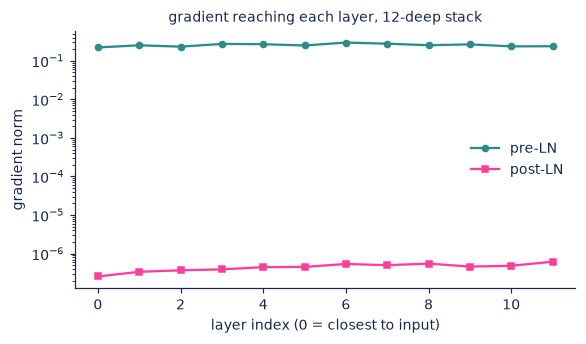

In [18]:
class Block(nn.Module):
    def __init__(self, d_model, n_heads, pre_ln=True, dropout=0.0):
        super().__init__()
        self.pre_ln = pre_ln
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ffn = FeedForward(d_model, dropout=dropout)
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)

    def forward(self, x, mask=None):
        if self.pre_ln:
            x = x + self.attn(self.ln1(x), mask)[0]
            x = x + self.ffn(self.ln2(x))
        else:
            x = self.ln1(x + self.attn(x, mask)[0])
            x = self.ln2(x + self.ffn(x))
        return x


def gradient_by_depth(pre_ln, n_layers=12, d=64):
    torch.manual_seed(0)
    layers = nn.ModuleList([Block(d, 4, pre_ln=pre_ln) for _ in range(n_layers)])
    x = torch.randn(4, 16, d)
    for layer in layers:
        x = layer(x)
    x.pow(2).mean().backward()
    return [layer.attn.qkv.weight.grad.norm().item() for layer in layers]

pre, post = gradient_by_depth(True), gradient_by_depth(False)

plt.figure(figsize=(5.4, 3.2))
plt.semilogy(pre,  "o-", color=TEAL, label="pre-LN", markersize=4)
plt.semilogy(post, "s-", color=PINK, label="post-LN", markersize=4)
plt.xlabel("layer index (0 = closest to input)"); plt.ylabel("gradient norm")
plt.title("gradient reaching each layer, 12-deep stack", fontsize=9)
plt.legend(frameon=False); plt.tight_layout(); plt.show()

print(f"  pre-LN  first/last layer gradient ratio: {pre[0]/pre[-1]:8.3f}")
print(f"  post-LN first/last layer gradient ratio: {post[0]/post[-1]:8.3f}")

Pre-LN delivers gradient of a comparable order to every layer in the stack. Post-LN does not, and the disparity gets worse the deeper you go. At twelve layers it's a training inconvenience you can warm up around. At ninety-six it's the difference between a model and a divergence.

## The encoder

Stack the blocks and you have an encoder. Every layer lets every position see every other position, so after $L$ layers each token's vector is a function of the entire sequence, refined $L$ times.

In [19]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=4,
                 max_len=512, dropout=0.0):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, d_model)
        self.register_buffer("pos", sinusoidal_encoding(max_len, d_model))
        self.blocks = nn.ModuleList(
            [Block(d_model, n_heads, pre_ln=True, dropout=dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)

    def forward(self, idx, mask=None):
        x = self.tok(idx) + self.pos[:idx.shape[1]]
        for block in self.blocks:
            x = block(x, mask)
        return self.ln_f(x)


enc = Encoder(len(VOCAB), d_model=64, n_heads=4, n_layers=3)
ids_a = torch.tensor([[stoi[w] for w in SENT_A]])
ids_b = torch.tensor([[stoi[w] for w in SENT_B]])
ea, eb = enc(ids_a), enc(ids_b)

print(f"encoder output shape: {tuple(ea.shape)}  (batch, tokens, d_model)")
print(f"parameters: {param_count(enc):,}\n")
print(f"cosine between the two 'bank' vectors:")
print(f"   straight from the embedding table : 1.0000")
print(f"   after three encoder layers        : "
      f"{F.cosine_similarity(ea[0, -1], eb[0, -1], dim=0):.4f}")

encoder output shape: (1, 7, 64)  (batch, tokens, d_model)
parameters: 149,952

cosine between the two 'bank' vectors:
   straight from the embedding table : 1.0000
   after three encoder layers        : 0.9814


There's the fix. It's worth being precise about what just happened though, because it's an easy one to misread. The embedding table still holds exactly one row for `bank`, unchanged. What the encoder gives you is not a lookup at all, it's a function of the whole sequence, and the same row comes out as two different vectors because the tokens around it differ.

The jargon for this is a **contextual** representation as opposed to a **static** one, and that distinction is pretty much the entire gap between word2vec and everything that came after it.

One thing to note though: this encoder is untrained, so what you're looking at is the architecture demonstrating that it *can* separate the two senses, not evidence that it has learned anything about rivers. We train one properly in Part 5.

# Part 4: The Decoder

## What goes wrong if everyone can see everything?

The encoder we just built is bidirectional: position 2 attends to position 6 as freely as to position 1. That's exactly right if your job is to understand a sentence you've been handed in full.

It's useless if your job is to produce one. A generative model predicts the next token, and if the layer computing that prediction can see the next token, the task is trivial and nothing is learned. The model would achieve zero loss by copying and generate nonsense the moment you asked it for a token that didn't exist yet.

The obvious fix is to train on prefixes: feed the first $t$ tokens, predict token $t+1$, repeat. But that throws away the thing we bought by deleting recurrence. A sequence of length $n$ would need $n$ separate forward passes, one per prefix, and we're back to serial computation.

**Causal masking** gets both. Run one forward pass over the whole sequence, but before the softmax, set every score where a query attends to a later key to $-\infty$. The softmax maps that to zero weight. Each position now computes its output as though it had only ever seen its own prefix, and all $n$ positions compute in parallel.

upper triangle of the causal weights is exactly zero: True
each row still sums to 1: True

position 0 attends to 1 token(s), position 6 attends to 7


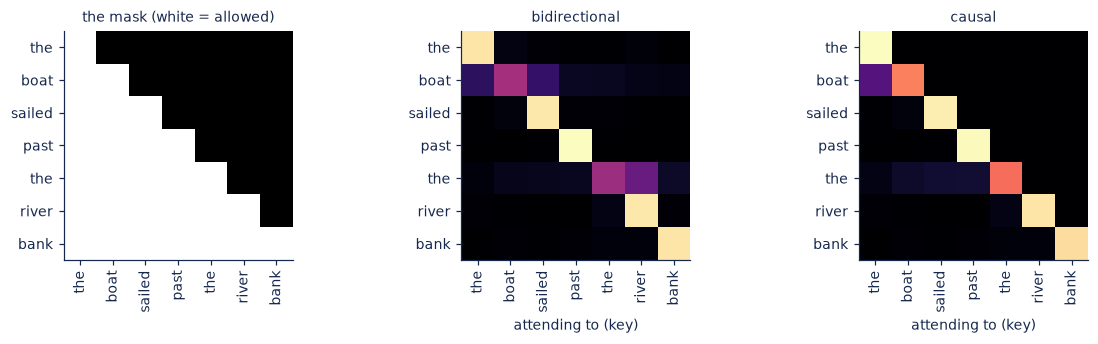

In [20]:
def causal_mask(n):
    """True where attention is allowed: query i may see key j only if j <= i."""
    return torch.tril(torch.ones(n, n, dtype=torch.bool))

n = 7
mask = causal_mask(n)
q = k = v = torch.randn(1, 1, n, 16)
_, w_free = scaled_dot_product_attention(q, k, v)
_, w_causal = scaled_dot_product_attention(q, k, v, mask)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].imshow(mask.numpy(), cmap="Greys_r"); axes[0].set_title("the mask (white = allowed)", fontsize=9)
show_attention(w_free[0, 0], SENT_A, "bidirectional", ax=axes[1])
show_attention(w_causal[0, 0], SENT_A, "causal", ax=axes[2])
for ax in axes[1:]:
    ax.set_ylabel("")
axes[0].set_xticks(range(n)); axes[0].set_xticklabels(SENT_A, rotation=90)
axes[0].set_yticks(range(n)); axes[0].set_yticklabels(SENT_A)
plt.tight_layout(); plt.show()

print(f"upper triangle of the causal weights is exactly zero: "
      f"{(w_causal[0,0].triu(1).abs().max() == 0).item()}")
print(f"each row still sums to 1: "
      f"{torch.allclose(w_causal.sum(-1), torch.ones(1,1,n), atol=1e-6)}")
print(f"\nposition 0 attends to {int((w_causal[0,0,0] > 0).sum())} token(s), "
      f"position {n-1} attends to {int((w_causal[0,0,-1] > 0).sum())}")

The triangular shape of that second heatmap is the single most recognisable image in modern machine learning, and now you know what it's for: it's the thing that makes training a generative model parallel.

That claim deserves a check rather than an assertion. If masked attention over the full sequence really is equivalent to running each prefix separately, the numbers should match exactly.

In [21]:
torch.manual_seed(2)
x = torch.randn(1, 6, d_model)
mha_c = MultiHeadAttention(d_model, 4)

# One pass over the whole sequence, masked.
full, _ = mha_c(x, mask=causal_mask(6))

# Six passes, each seeing only its own prefix.
prefix_outputs = []
for t in range(1, 7):
    out_t, _ = mha_c(x[:, :t, :], mask=causal_mask(t))
    prefix_outputs.append(out_t[:, -1, :])      # keep only the last position
prefixwise = torch.stack(prefix_outputs, dim=1)

print(f"one masked pass vs {6} prefix passes")
print(f"  identical: {torch.allclose(full, prefixwise, atol=1e-6)}")
print(f"  max diff : {(full - prefixwise).abs().max():.2e}")
print(f"\nso we get {6} training signals from 1 forward pass instead of {6}.")

one masked pass vs 6 prefix passes
  identical: True
  max diff : 5.96e-08

so we get 6 training signals from 1 forward pass instead of 6.


Exactly equal, which is the whole trick. Every position in the sequence is a training example, all of them are computed in one pass, and none of them can cheat. A 1024-token sequence yields 1024 next-token predictions for the price of one forward pass, and that efficiency is a large part of why language models scaled the way they did.

## Cross-attention: reading from somewhere else

The decoder in the original paper has a second attention sublayer, and it's the direct descendant of Bahdanau's patch from Part 1.

The distinction is only about where the three inputs come from. In self-attention, $Q$, $K$ and $V$ are all projections of the same sequence. In **cross-attention**, the queries come from the decoder and the keys and values come from the encoder's output.

Read that as: the decoder asks the question, the source sentence answers it. Which is precisely "let the decoder look back at the source", now written as a standard layer rather than a special mechanism.

One consequence worth noticing: cross-attention needs no causal mask. Looking at the entire source is not cheating, because the source is input, not something we're predicting.

In [22]:
class DecoderBlock(nn.Module):
    """Three sublayers: masked self-attention, optional cross-attention, FFN."""
    def __init__(self, d_model, n_heads, cross=True, dropout=0.0):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ln1 = nn.LayerNorm(d_model)
        self.cross = cross
        if cross:
            self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
            self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, dropout=dropout)
        self.ln3 = nn.LayerNorm(d_model)

    def forward(self, x, memory=None, self_mask=None):
        x = x + self.self_attn(self.ln1(x), mask=self_mask)[0]        # masked, causal
        if self.cross:
            x = x + self.cross_attn(self.ln2(x), kv=memory)[0]        # unmasked, reads source
        x = x + self.ffn(self.ln3(x))
        return x


src = torch.randn(1, 9, d_model)      # a 9-token source sentence, encoded
tgt = torch.randn(1, 5, d_model)      # 5 tokens generated so far
block = DecoderBlock(d_model, 4)
out = block(tgt, memory=src, self_mask=causal_mask(5))

print(f"source (encoder memory): {tuple(src.shape)}")
print(f"target so far          : {tuple(tgt.shape)}")
print(f"decoder block output   : {tuple(out.shape)}   <- target length, not source length")
print("\nthe queries set the output length; keys and values only supply content.")

source (encoder memory): (1, 9, 24)
target so far          : (1, 5, 24)
decoder block output   : (1, 5, 24)   <- target length, not source length

the queries set the output length; keys and values only supply content.


That last line is the mental model worth keeping. The query sequence determines the shape of what comes out. The key/value sequence determines what's available to put in it. Once you have that, cross-attention stops being a separate concept and becomes an argument you pass.

## Teacher forcing, and the gap it leaves

One more thing about training a decoder, because it's where a real discrepancy hides.

During training we feed the *correct* previous tokens and ask for the next one, even when the model would have predicted something else. This is **teacher forcing**, and the causal mask is what implements it efficiently.

At inference there is no correct previous token. The model consumes its own output, one step at a time.

In [23]:
print("training (teacher forcing), one parallel pass:")
target = ["the", "cat", "sat", "on"]
for t in range(len(target)):
    given = " ".join(target[:t]) or "<start>"
    print(f"   given {given:<22} -> predict '{target[t]}'      (given text is always correct)")

print("\ninference, strictly sequential:")
generated = []
for t in range(len(target)):
    given = " ".join(generated) or "<start>"
    generated.append(target[t] if t < 2 else "wrong")
    print(f"   given {given:<22} -> model said '{generated[-1]}'"
          f"{'   <- and now the prefix is off-distribution' if generated[-1]=='wrong' and t==2 else ''}")

training (teacher forcing), one parallel pass:
   given <start>                -> predict 'the'      (given text is always correct)
   given the                    -> predict 'cat'      (given text is always correct)
   given the cat                -> predict 'sat'      (given text is always correct)
   given the cat sat            -> predict 'on'      (given text is always correct)

inference, strictly sequential:
   given <start>                -> model said 'the'
   given the                    -> model said 'cat'
   given the cat                -> model said 'wrong'   <- and now the prefix is off-distribution
   given the cat wrong          -> model said 'wrong'


The mismatch has a name, **exposure bias**: the model is only ever trained on prefixes that are correct, so at generation time a single mistake puts it on a prefix unlike anything it saw in training.

In practice large models cope well enough that it's tolerable, and the fixes (scheduled sampling and friends) never really caught on. It does explain a failure mode you'll recognise though, where a model that was doing fine goes off the rails and then compounds the error confidently for several paragraphs.

It also has a direct consequence for Part 6. Training is one parallel pass over $n$ positions. Generation is $n$ sequential passes, each producing exactly one token. Those two workloads look nothing alike on a profile, and the second one is where the serving cost lives.

# Part 5: How It Pairs Up Into The Models We Actually Use

## Three ways to arrange the same parts

We now have both halves. What's striking is that essentially every model you've heard of is one of three arrangements of them, and the choice of arrangement is mostly a choice about masking.

**Encoder-only** (BERT, RoBERTa, and every embedding model in your retrieval stack). Bidirectional attention, no mask. Every token sees the whole sequence in both directions, which gives the richest possible representation of text you already have. It cannot generate, because there's no notion of "next". Trained by masking out random tokens and reconstructing them.

**Decoder-only** (GPT, Llama, Claude, Gemini, Mistral, essentially all of them). Causal attention, nothing else. No separate encoder, no cross-attention. Input and output are the same stream, and "understanding the prompt" is just the forward pass over the prompt tokens. Trained by predicting the next token.

**Encoder-decoder** (the original 2017 model, T5, BART, most translation systems). An encoder reads the source bidirectionally, a decoder generates with causal self-attention plus cross-attention into the encoder. The natural shape when input and output are genuinely different objects.

In [24]:
V_demo, d_demo, h_demo, L_demo = 32000, 512, 8, 6

enc_only = Encoder(V_demo, d_demo, h_demo, L_demo)
dec_only = nn.ModuleList([DecoderBlock(d_demo, h_demo, cross=False) for _ in range(L_demo)])
enc_dec_e = Encoder(V_demo, d_demo, h_demo, L_demo)
enc_dec_d = nn.ModuleList([DecoderBlock(d_demo, h_demo, cross=True) for _ in range(L_demo)])

emb = V_demo * d_demo
rows = [
    ("encoder-only",    param_count(enc_only),                                "none",      "no"),
    ("decoder-only",    param_count(dec_only) + emb,                          "causal",    "yes"),
    ("encoder-decoder", param_count(enc_dec_e) + param_count(enc_dec_d) + emb,"both",      "yes"),
]
print(f"{L_demo} layers, d_model={d_demo}, vocab={V_demo:,}\n")
print(f"  {'architecture':<18}{'parameters':>14}{'masking':>12}{'generates?':>13}")
for name, p, m, g in rows:
    print(f"  {name:<18}{p:>14,}{m:>12}{g:>13}")

print(f"\n  encoder-decoder carries roughly "
      f"{rows[2][1]/rows[1][1]:.1f}x the parameters of decoder-only at equal depth,")
print(f"  because it pays for two stacks plus the cross-attention between them.")

6 layers, d_model=512, vocab=32,000

  architecture          parameters     masking   generates?
  encoder-only          35,287,040        none           no
  decoder-only          35,286,016      causal          yes
  encoder-decoder       76,870,656        both          yes

  encoder-decoder carries roughly 2.2x the parameters of decoder-only at equal depth,
  because it pays for two stacks plus the cross-attention between them.


## So why did decoder-only win?

For a few years it genuinely wasn't obvious that it would. Encoder-decoder is the better-motivated design for translation, and BERT dominated everything that wasn't generation. The reasons decoder-only took over are worth laying out, because none of them is "it produces better representations".

**It has a single training objective that works on raw text.** Predict the next token. No masking strategy to tune, no paired source and target, no supervision at all. Every document on the internet is training data in its native form, and the objective is identical at every scale. When the thing that limits you is how much text you can pour in, this matters more than architectural elegance.

**Everything becomes one modality.** Translation, summarisation, question answering and code completion stop being different tasks with different heads and become the same task: continue this text. That's what makes prompting possible. You are not configuring the model, you are writing a prefix that makes the desired continuation the likely one.

**It's half the machinery.** No cross-attention sublayer, one stack rather than two, one vocabulary. Simpler to implement, simpler to shard across devices, simpler to serve.

**The KV cache is clean.** We'll meet this properly in Part 6, but briefly: with a single causal stack, every key and value you compute while reading the prompt is reusable for every subsequent token. That makes incremental generation cheap in a way the two-stack design complicates.

The cost is real, mind. Causal masking means that when the model reads your prompt, token 5 never sees token 50. A bidirectional encoder would give a strictly better representation of a fixed input, which is why retrieval and classification still frequently use encoder-only models. The field accepted a worse representation in exchange for an objective that scales, and that trade is most of the story of the last six years.

## Build one and train it

Enough architecture. Let's assemble a decoder-only model and train it on the same Tiny Shakespeare corpus we used for the tokenizer and the embeddings, so the comparison is honest.

Character-level, to keep the vocabulary small and the runtime short.

In [25]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
FALLBACK = ("To be, or not to be, that is the question:\n"
            "Whether 'tis nobler in the mind to suffer\n"
            "The slings and arrows of outrageous fortune,\n"
            "Or to take arms against a sea of troubles\n") * 400
try:
    text = urllib.request.urlopen(URL, timeout=30).read().decode()
    source = "Tiny Shakespeare (downloaded)"
except Exception as e:
    text = FALLBACK
    source = f"built-in fallback ({type(e).__name__}, no network)"

chars = sorted(set(text))
ctoi = {c: i for i, c in enumerate(chars)}
itoc = {i: c for c, i in ctoi.items()}
data = torch.tensor([ctoi[c] for c in text], dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]

print(f"source     : {source}")
print(f"characters : {len(text):,}")
print(f"vocabulary : {len(chars)} distinct characters")
print(f"train/val  : {len(train_data):,} / {len(val_data):,}")

source     : Tiny Shakespeare (downloaded)
characters : 1,115,394
vocabulary : 65 distinct characters
train/val  : 1,003,854 / 111,540


In [26]:
class TinyGPT(nn.Module):
    """A decoder-only transformer. The same shape as GPT-2, several orders smaller."""
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=4,
                 block_size=128, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok = nn.Embedding(vocab_size, d_model)
        self.pos = nn.Embedding(block_size, d_model)          # learned, as GPT does
        self.blocks = nn.ModuleList(
            [DecoderBlock(d_model, n_heads, cross=False, dropout=dropout)
             for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok.weight                    # weight tying
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        # Without this, tied embeddings keep torch's default N(0,1), the initial
        # logits have std ~sqrt(d_model), and step-0 loss starts near 85 instead
        # of ln(vocab). GPT-2 uses 0.02 and so do we.
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok(idx) + self.pos(torch.arange(T, device=idx.device))
        m = causal_mask(T).to(idx.device)
        for block in self.blocks:
            x = block(x, self_mask=m)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]          # never exceed the window
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature       # only the last position matters
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            probs = F.softmax(logits, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx


BLOCK, BATCH = 128, 32
model = TinyGPT(len(chars), d_model=128, n_heads=4, n_layers=4, block_size=BLOCK).to(DEVICE)
print(f"parameters: {param_count(model):,}")
print(f"context window: {BLOCK} characters")

parameters: 816,000
context window: 128 characters


In [27]:
def get_batch(split_data):
    ix = torch.randint(len(split_data) - BLOCK - 1, (BATCH,))
    x = torch.stack([split_data[i:i+BLOCK] for i in ix])
    y = torch.stack([split_data[i+1:i+BLOCK+1] for i in ix])    # shifted by one
    return x.to(DEVICE), y.to(DEVICE)


opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)
STEPS = 1500
t0 = time.time()
history = []

for step in range(STEPS + 1):
    xb, yb = get_batch(train_data)
    _, loss = model(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()

    if step % 250 == 0:
        model.eval()
        with torch.no_grad():
            vl = torch.stack([model(*get_batch(val_data))[1] for _ in range(10)]).mean()
        model.train()
        history.append((step, loss.item(), vl.item()))
        print(f"  step {step:>5}   train {loss.item():.3f}   val {vl:.3f}   "
              f"({time.time()-t0:5.1f}s)")

print(f"\ntrained in {time.time()-t0:.1f}s")
print(f"random-guess loss would be ln({len(chars)}) = {math.log(len(chars)):.3f}")

  step     0   train 4.170   val 3.917   (  0.4s)
  step   250   train 2.472   val 2.446   ( 25.9s)
  step   500   train 2.318   val 2.292   ( 48.9s)
  step   750   train 2.182   val 2.199   ( 74.5s)
  step  1000   train 2.094   val 2.084   (103.4s)
  step  1250   train 2.001   val 1.992   (127.1s)
  step  1500   train 1.901   val 1.925   (149.1s)

trained in 149.1s
random-guess loss would be ln(65) = 4.174


The loss falling well below $\ln(V)$ means the model has learned structure rather than the character frequencies.

One thing to note though, and it's a trap I walked straight into building this notebook: if you leave the weight initialisation at PyTorch's default, the tied embedding starts at $N(0,1)$, the initial logits come out with a standard deviation around $\sqrt{d_{\text{model}}}$, and step 0 loss lands near 85 instead of $\ln(65) = 4.17$.

The model still trains and still writes text, it just burns its first few hundred steps shrinking logits instead of learning anything. That's what `_init_weights` above is for, and 0.02 is the value GPT-2 uses.

Quiet failures like that are the ones to watch for, because nothing raises an exception. Let's see what it writes.

In [28]:
start = torch.zeros((1, 1), dtype=torch.long, device=DEVICE)
out = model.generate(start, max_new_tokens=400, temperature=0.8, top_k=20)
print("".join(itoc[i] for i in out[0].tolist()))


Astred: be that deeve bestires,
To all you thou of what so you,
Has sir, thy a tis gooth of thy hand the the see
am at done of boother'd buth with meed?
Ther the orgaive, boolod, the I most thou
And have and the mises slacking in hif ous polees
The lon ware ou combes grue do a deersh withian,
Thath but his old her them forther.

QUEEN APURET:
Has his ever withe the sin swill, that was ash,
Now, th


It's not Shakespeare. It is, from a four-layer model trained for about two and a half minutes on a laptop CPU, recognisably *shaped* like Shakespeare: alternating speaker lines, colons after names, plausible word lengths, roughly English orthography. All of that came from next-character prediction and nothing else.

Scale that architecture up by five orders of magnitude, train it on a corpus of trillions of tokens rather than a megabyte, and the structure it learns stops being orthographic and starts being semantic. The mechanism doesn't change. This is genuinely the same forward pass that runs in a frontier model, and the parts that differ (RoPE instead of learned positions, grouped-query attention, SwiGLU in the FFN, RMSNorm) are refinements to the block, not a different idea.

Which brings us to the thing that actually gets in the way of scaling it.

# Part 6: The Systems Reality (Why Attention Is Expensive)

## Connecting the dots: where the cost actually comes from

In the embeddings notebook we made the case that the embedding table is the one part of a model that behaves nothing like the rest of it: all parameters, no FLOPs, pinned against memory bandwidth. Attention is the other anomaly, and it's anomalous in a different way.

If you notice, every other layer in a transformer is **linear** in sequence length. Feed it twice as many tokens and it does twice the work, because it handles each position independently. The FFN, the projections, the embedding lookup, the output head: all linear.

Attention is not, and we can't make it so without changing what it computes. The definition says every query attends to every key. With $n$ queries and $n$ keys that's $n^2$ scores, and there's no way to get the exact result with fewer of them, because each one is genuinely part of the answer.

So let's measure that cost rather than assert it.

   seq len   time (ms)   vs previous    (2x would be linear)
       128        0.32             -
       256        0.88         2.75x
       512        6.33         7.20x
      1024       31.47         4.97x
      2048      134.78         4.28x


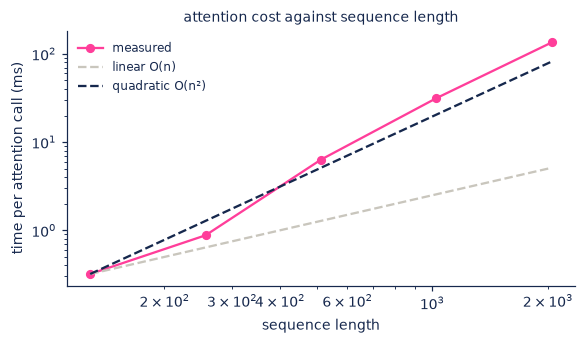

In [29]:
def time_attention(n, d=64, heads=8, reps=5):
    q = k = v = torch.randn(1, heads, n, d)
    scaled_dot_product_attention(q, k, v)            # warm up
    t0 = time.time()
    for _ in range(reps):
        scaled_dot_product_attention(q, k, v)
    return (time.time() - t0) / reps


lengths = [128, 256, 512, 1024, 2048]
times = [time_attention(n) for n in lengths]

print(f"  {'seq len':>8}{'time (ms)':>12}{'vs previous':>14}{'(2x would be linear)':>24}")
prev = None
for n, t in zip(lengths, times):
    ratio = f"{t/prev:.2f}x" if prev else "-"
    print(f"  {n:>8}{t*1e3:>12.2f}{ratio:>14}")
    prev = t

plt.figure(figsize=(5.4, 3.2))
plt.loglog(lengths, [t*1e3 for t in times], "o-", color=PINK, label="measured", markersize=5)
base = times[0] * 1e3
plt.loglog(lengths, [base * (n/lengths[0])    for n in lengths], "--", color=GREY, label="linear O(n)")
plt.loglog(lengths, [base * (n/lengths[0])**2 for n in lengths], "--", color=INK,  label="quadratic O(n²)")
plt.xlabel("sequence length"); plt.ylabel("time per attention call (ms)")
plt.title("attention cost against sequence length", fontsize=9)
plt.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

Each doubling of sequence length costs roughly four times the time, not two. On a log-log plot the measurements track the quadratic reference line rather than the linear one. At short lengths the curve sits below it, because small matrices don't saturate the hardware and you're measuring overhead rather than arithmetic, but the asymptote is unambiguous.

## So why does it hurt in memory rather than arithmetic?

The timing is the visible symptom. The real constraint is that naive attention has to **materialise** the $n \times n$ score matrix in memory before it can softmax it, and that matrix exists per head, per layer, per sequence in the batch.

This is the number that decides what hardware you need.

In [30]:
def attn_matrix_bytes(n, batch, heads, dtype_bytes=2):
    return batch * heads * n * n * dtype_bytes


print("memory for the attention score matrix alone, one layer, bf16")
print("(not the weights, not the activations, not the KV cache, just the scores)\n")
print(f"  {'seq len':>9}{'batch 1':>12}{'batch 8':>12}{'batch 32':>12}")
for n in [512, 2048, 8192, 32768, 131072]:
    row = "".join(f"{attn_matrix_bytes(n, b, 32)/1e9:>11.2f}G" for b in (1, 8, 32))
    print(f"  {n:>9}{row}")

print(f"\n  an 80 GB accelerator, one layer, batch 1, 32 heads:")
for n in [8192, 32768, 131072]:
    gb = attn_matrix_bytes(n, 1, 32) / 1e9
    verdict = "fits" if gb < 80 else f"needs {gb/80:.0f}x the card"
    print(f"    {n:>7} tokens -> {gb:>8.1f} GB   {verdict}")

memory for the attention score matrix alone, one layer, bf16
(not the weights, not the activations, not the KV cache, just the scores)

    seq len     batch 1     batch 8    batch 32
        512       0.02G       0.13G       0.54G
       2048       0.27G       2.15G       8.59G
       8192       4.29G      34.36G     137.44G
      32768      68.72G     549.76G    2199.02G
     131072    1099.51G    8796.09G   35184.37G

  an 80 GB accelerator, one layer, batch 1, 32 heads:
       8192 tokens ->      4.3 GB   fits
      32768 tokens ->     68.7 GB   fits
     131072 tokens ->   1099.5 GB   needs 14x the card


A 128k context at batch 1 wants over a terabyte for one layer's scores, and a real model has dozens of layers. This is why long context was not simply a matter of deciding to support it, and why the entire 2022 to 2024 run of optimisation work was aimed squarely at never writing that matrix down.

Worth noticing where the crossover sits, because it explains why the 2017 paper was relaxed about all this.

In [31]:
d_model_x, ffn_mult = 4096, 4
print("FLOPs per layer, decomposed (d_model = 4096)\n")
print(f"  {'seq len':>9}{'linear parts':>16}{'attention':>14}{'attention share':>18}")
for n in [512, 2048, 8192, 32768, 131072]:
    linear = n * d_model_x**2 * (4 + 2 * ffn_mult)      # qkv+proj and the FFN
    attn = 2 * n**2 * d_model_x                         # scores and the weighted sum
    print(f"  {n:>9}{linear:>16.2e}{attn:>14.2e}{attn/(linear+attn):>17.0%}")

print(f"\n  the two terms are equal when 2n²d = 12nd², i.e. at n = 6·d_model = {6*d_model_x:,} tokens.")
print(f"  at n=512 (the 2017 setting) attention is a rounding error. at n=131072 it's almost everything.")

FLOPs per layer, decomposed (d_model = 4096)

    seq len    linear parts     attention   attention share
        512        1.03e+11      2.15e+09               2%
       2048        4.12e+11      3.44e+10               8%
       8192        1.65e+12      5.50e+11              25%
      32768        6.60e+12      8.80e+12              57%
     131072        2.64e+13      1.41e+14              84%

  the two terms are equal when 2n²d = 12nd², i.e. at n = 6·d_model = 24,576 tokens.
  at n=512 (the 2017 setting) attention is a rounding error. at n=131072 it's almost everything.


At the paper's own sequence length, attention is a small minority of the arithmetic, which is exactly why "complexity per layer $O(n^2 d)$" appeared in a table without alarm. The architecture was designed in a regime where the quadratic term didn't bite. Everything since has been spent outside that regime.

## Arithmetic intensity, and why the matmul units sit idle

The embeddings notebook introduced the roofline idea: a kernel is compute-bound or memory-bound depending on how many FLOPs it performs per byte it moves. Embedding lookups scored zero, pinning them against bandwidth.

Attention is more interesting, because its intensity depends on what you're doing.

In [32]:
def intensity(flops, bytes_moved):
    return flops / bytes_moved


d_h, n_h = 128, 32
RIDGE = 200          # roughly where a modern accelerator stops being memory-bound

print(f"  {'operation':<34}{'FLOPs/byte':>12}{'bound by':>14}")

# Prefill / training: one pass over many tokens at once.
for n in [512, 4096, 16384]:
    f = 2 * 2 * n * n * d_h * n_h                      # scores, then weighted sum
    b = 2 * (3 * n * d_h * n_h + n * n * n_h)          # q,k,v in and the score matrix out
    ai = intensity(f, b)
    print(f"  {'prefill attention, n=' + str(n):<34}{ai:>12.1f}"
          f"{('compute' if ai > RIDGE else 'memory'):>14}")

# Decode: one new token attending to the whole cache.
for n in [512, 4096, 16384]:
    f = 2 * 2 * 1 * n * d_h * n_h
    b = 2 * (2 * n * d_h * n_h)                        # the whole cache gets read
    ai = intensity(f, b)
    print(f"  {'decode one token, cache=' + str(n):<34}{ai:>12.1f}"
          f"{('compute' if ai > RIDGE else 'memory'):>14}")

print(f"\n  a modern accelerator needs roughly {RIDGE}+ FLOPs/byte to stay compute-bound.")
print(f"  prefill gets there once the sequence is long enough to amortise the projections.")
print(f"  decode sits at 1.0 and STAYS there: the cache it reads and the work it does")
print(f"  both grow with context, so the ratio never improves. that's the whole problem.")

  operation                           FLOPs/byte      bound by
  prefill attention, n=512                 146.3        memory
  prefill attention, n=4096                234.1       compute
  prefill attention, n=16384               250.1       compute
  decode one token, cache=512                1.0        memory
  decode one token, cache=4096               1.0        memory
  decode one token, cache=16384              1.0        memory

  a modern accelerator needs roughly 200+ FLOPs/byte to stay compute-bound.
  prefill gets there once the sequence is long enough to amortise the projections.
  decode sits at 1.0 and STAYS there: the cache it reads and the work it does
  both grow with context, so the ratio never improves. that's the whole problem.


There's the split that governs inference economics. Reading the prompt is a big parallel matmul that uses the hardware well. Generating each subsequent token is a thin, **memory-bound** operation that reads the entire cache just to produce one token, with the matrix units sitting mostly idle while it happens.

Run a workload that is all decode and no prefill and you'll see a quite noticeable performance hit, for reasons that have nothing to do with how many FLOPs your accelerator can manage.

That asymmetry is why time-to-first-token and tokens-per-second are quoted as separate metrics, why batching helps decode so disproportionately (more work per byte read), and why serving cost per token barely tracks the FLOP count at all.

## The KV cache

One more structure, and it's the one that usually decides how many concurrent users fit on a card.

During generation, step $t$ recomputes keys and values for every token in the prefix, which is wasteful because those tokens haven't changed since the last step. The standard fix is to cache them, and that's what the **KV cache** is. It converts per-token cost from quadratic to linear, and it's not optional at any reasonable scale.

What it costs is memory that grows with every token generated, for every sequence in flight, and unlike the weights it cannot be shared between users.

In [33]:
def kv_cache_gb(n_tokens, n_layers, n_heads, d_head, batch=1, dtype_bytes=2):
    return 2 * batch * n_layers * n_heads * d_head * n_tokens * dtype_bytes / 1e9


configs = [
    ("7B-class   (32L, 32H, 128d)", 32, 32, 128),
    ("13B-class  (40L, 40H, 128d)", 40, 40, 128),
    ("70B-class  (80L, 64H, 128d)", 80, 64, 128),
]
print("KV cache size in GB, bf16, single sequence\n")
print(f"  {'model':<30}{'4k ctx':>10}{'32k ctx':>10}{'128k ctx':>11}")
for name, L, H, D in configs:
    row = "".join(f"{kv_cache_gb(n, L, H, D):>10.1f}" for n in (4096, 32768, 131072))
    print(f"  {name:<30}{row}")

print(f"\n  the 70B-class model on an 8-card node of 80 GB each (640 GB):")
weights = 70e9 * 2 / 1e9                      # bf16, one shared copy
free = 640 - weights
print(f"    weights (shared by everyone) {weights:>8.0f} GB")
print(f"    left over for KV cache       {free:>8.0f} GB")
for ctx in (4096, 32768, 131072):
    per_user = kv_cache_gb(ctx, 80, 64, 128)
    print(f"    concurrent users at {ctx:>6} ctx {int(free // per_user):>8}"
          f"   ({per_user:.1f} GB each)")

KV cache size in GB, bf16, single sequence

  model                             4k ctx   32k ctx   128k ctx
  7B-class   (32L, 32H, 128d)          2.1      17.2      68.7
  13B-class  (40L, 40H, 128d)          3.4      26.8     107.4
  70B-class  (80L, 64H, 128d)         10.7      85.9     343.6

  the 70B-class model on an 8-card node of 80 GB each (640 GB):
    weights (shared by everyone)      140 GB
    left over for KV cache            500 GB
    concurrent users at   4096 ctx       46   (10.7 GB each)
    concurrent users at  32768 ctx        5   (85.9 GB each)
    concurrent users at 131072 ctx        1   (343.6 GB each)


The weights are a fixed cost you pay once and amortise over everyone. The KV cache is per-user and grows as the conversation does, so on a long-context workload it is frequently *larger* than the model, and it is what sets your maximum batch size, which sets your throughput, which sets your cost per token.

This is the clearest example of a theme running through the whole series. A property of the maths (every token attends to every token) becomes a property of the memory system (a cache linear in context and in users) and ends up as a line item in a budget.

## What this sets up

Pulling the whole part together, naive attention has four distinct problems and they're worth separating because the fixes are different:

1. **Quadratic time.** $n^2$ score computations per head per layer. Fundamental to the definition, given that the result must be exact.
2. **Quadratic memory.** The materialised $n \times n$ matrix, which is an artifact of how the computation is *staged*, not of what it computes. This one has a clean answer.
3. **Memory-bound decoding.** Arithmetic intensity around 1 during generation, so the hardware runs at a small fraction of peak no matter how fast it is.
4. **A KV cache linear in context and users.** Caps concurrency, dominates memory on long-context serving.

Notice that only the first of those is actually inherent. The other three are consequences of a particular implementation of exact attention, and all three have been substantially improved without changing a single output value.

Pulling that apart is the next notebook: tiling the computation so the big matrix is never written to memory, compressing the cache by sharing keys and values across heads, and deciding when an approximation is worth taking. Then what those choices do to the hardware you buy and the way you serve, which is the part that actually shows up on an invoice.

## Where to next?

We started with a lookup table that gave `bank` one vector regardless of context, and ended with a mechanism that rewrites every token's representation as a weighted average over the whole sequence, where the weights are learned and contextual. The polysemy complaint from the embeddings notebook is resolved. Word order, the other thing a bag of vectors can't see, is handled by positional encoding.

The pieces, in the order we needed them:

- **Attention** is a weighted average over value vectors, where the weights come from a softmax over query-key similarities. Six lines of tensor code.
- **Q, K and V** are three learned projections of the same input, because searching, being findable, and being retrieved are different jobs.
- **$\sqrt{d_k}$** keeps the softmax out of saturation, where it would stop passing gradient.
- **Multi-head** gives several notions of relevance at once, for the same parameter count.
- **Positional encoding** restores the ordering we deleted along with the recurrence.
- **Residuals, LayerNorm and the FFN** are what make the block trainable and give it capacity. The FFN holds two thirds of the parameters.
- **Causal masking** is the thing that makes generative training parallel: $n$ predictions from one forward pass, none of them cheating.
- **Decoder-only** won on the strength of its training objective rather than its representations.
- **The quadratic** is inherent to exact attention. The memory blow-up, the memory-bound decode and the KV cache are not inherent, and they're next.

The next notebook takes those four problems in order and goes after the three that are tractable, then follows the consequences out into infrastructure: what changes about the accelerator you want, how batching and scheduling work when decode is bandwidth-bound, and why context length shows up in pricing.

Meanwhile, the sources behind this notebook:

- [Attention Is All You Need](https://arxiv.org/abs/1706.03762) (Vaswani, Shazeer, Parmar, Uszkoreit, Jones, Gomez, Kaiser, Polosukhin, NeurIPS 2017), the one this is all about
- [Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473) (Bahdanau, Cho, Bengio, 2014), where attention was introduced as a patch for the bottleneck
- [Sequence to Sequence Learning with Neural Networks](https://arxiv.org/abs/1409.3215) (Sutskever, Vinyals, Le, NeurIPS 2014), the fixed-vector design attention was reacting to
- [Long Short-Term Memory](https://www.bioinf.jku.at/publications/older/2604.pdf) (Hochreiter and Schmidhuber, 1997), the gating that stretched recurrence as far as it would go
- [BERT: Pre-training of Deep Bidirectional Transformers](https://arxiv.org/abs/1810.04805) (Devlin, Chang, Lee, Toutanova, NAACL 2019), the encoder-only branch
- [Improving Language Understanding by Generative Pre-Training](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf) (Radford, Narasimhan, Salimans, Sutskever, 2018), the decoder-only branch
- [Language Models are Few-Shot Learners](https://arxiv.org/abs/2005.14165) (Brown et al., NeurIPS 2020), where decoder-only plus scale turned into prompting
- [On Layer Normalization in the Transformer Architecture](https://arxiv.org/abs/2002.04745) (Xiong et al., ICML 2020), the pre-LN versus post-LN analysis we measured
- [RoFormer: Enhanced Transformer with Rotary Position Embedding](https://arxiv.org/abs/2104.09864) (Su et al., 2021), the positional scheme most new models use
- [Efficient Transformers: A Survey](https://arxiv.org/abs/2009.06732) (Tay, Dehghani, Bahri, Metzler, 2020), a good map of the territory the next notebook covers
- [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) (Jay Alammar), still the best visual walkthrough
- [Let's build GPT: from scratch, in code, spelled out](https://www.youtube.com/watch?v=kCc8FmEb1nY) (Andrej Karpathy), which the Part 5 model is deliberately close to